# Market Basket Analysis

Bakery Sales Dataset: https://www.kaggle.com/datasets/akashdeepkuila/bakery

Inspiration on dashboard visualiszations: https://medium.com/@samuelegbeola/the-bread-basket-bakery-analysis-project-f4543275ef52

In [42]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load data
items = pd.read_csv('bakery_sales_dataset/bakery_sales_revised.csv')

items.head(10)

,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,10/30/2016 9:58,morning,weekend
1,2,Scandinavian,10/30/2016 10:05,morning,weekend
2,2,Scandinavian,10/30/2016 10:05,morning,weekend
3,3,Hot chocolate,10/30/2016 10:07,morning,weekend
4,3,Jam,10/30/2016 10:07,morning,weekend
5,3,Cookies,10/30/2016 10:07,morning,weekend
6,4,Muffin,10/30/2016 10:08,morning,weekend
7,5,Coffee,10/30/2016 10:13,morning,weekend
8,5,Pastry,10/30/2016 10:13,morning,weekend
9,5,Bread,10/30/2016 10:13,morning,weekend


In [3]:
items.shape

(20507, 5)

In [4]:
items.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB


In [5]:
# create detailed date columns
items['date_time'] = items['date_time'].apply(pd.Timestamp)
items['date'] = items['date_time'].dt.date
items['time'] = items['date_time'].dt.time
items['year'] = items['date_time'].dt.year
items['month'] = items['date_time'].dt.month
items['year_month'] = items['date_time'].map(lambda x: str(x.year) + '-' + str(x.month))
items['day_of_week'] = items['date_time'].dt.dayofweek
items['day_name'] = items['date_time'].dt.day_name()
items['hour'] = items['date_time'].dt.hour
items['week_number'] = items['date_time'].dt.isocalendar().week

items.sample(10)

,Transaction,Item,date_time,period_day,weekday_weekend,date,time,year,month,year_month,day_of_week,day_name,hour,week_number
14565,7019,Bread,2017-02-22 15:06:00,afternoon,weekday,2017-02-22,15:06:00,2017,2,2017-2,2,Wednesday,15,8
9532,4783,Bread,2017-01-16 10:12:00,morning,weekday,2017-01-16,10:12:00,2017,1,2017-1,0,Monday,10,3
15449,7386,Bread,2017-03-01 12:06:00,afternoon,weekday,2017-03-01,12:06:00,2017,3,2017-3,2,Wednesday,12,9
19519,9230,Extra Salami or Feta,2017-04-01 17:30:00,evening,weekend,2017-04-01,17:30:00,2017,4,2017-4,5,Saturday,17,13
12033,5960,Soup,2017-02-04 14:18:00,afternoon,weekend,2017-02-04,14:18:00,2017,2,2017-2,5,Saturday,14,5
4097,2007,Keeping It Local,2016-11-25 09:44:00,morning,weekday,2016-11-25,09:44:00,2016,11,2016-11,4,Friday,9,47
13581,6623,Coffee,2017-02-15 15:26:00,afternoon,weekday,2017-02-15,15:26:00,2017,2,2017-2,2,Wednesday,15,7
11644,5787,Coffee,2017-02-02 11:07:00,morning,weekday,2017-02-02,11:07:00,2017,2,2017-2,3,Thursday,11,5
16089,7656,Tea,2017-03-05 15:11:00,afternoon,weekend,2017-03-05,15:11:00,2017,3,2017-3,6,Sunday,15,9
9586,4819,Coffee,2017-01-17 09:24:00,morning,weekday,2017-01-17,09:24:00,2017,1,2017-1,1,Tuesday,9,3


## Exploratory Data Analysis

Text(0.5, 1.0, 'Number of transactions by month')

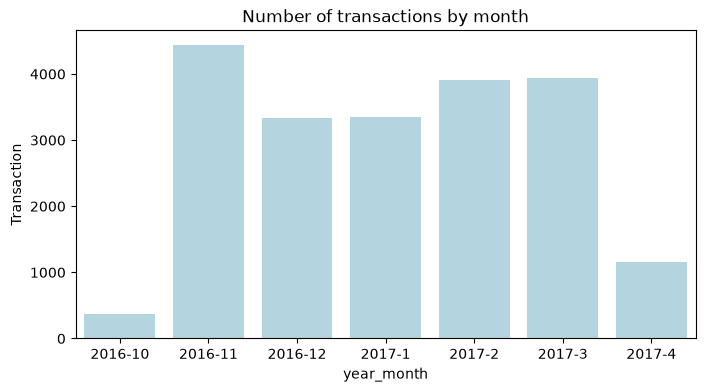

In [6]:
# Total transactions by month

transaction_by_month = items[['year_month', 'Transaction']].groupby('year_month', as_index=False).count()

plt.figure(figsize=(8, 4))

sns.barplot(x='year_month', y='Transaction', data=transaction_by_month, color='lightblue')

plt.ticklabel_format(style='plain', axis='y')
plt.title('Number of transactions by month')

Text(0.5, 1.0, 'Transactions by day')

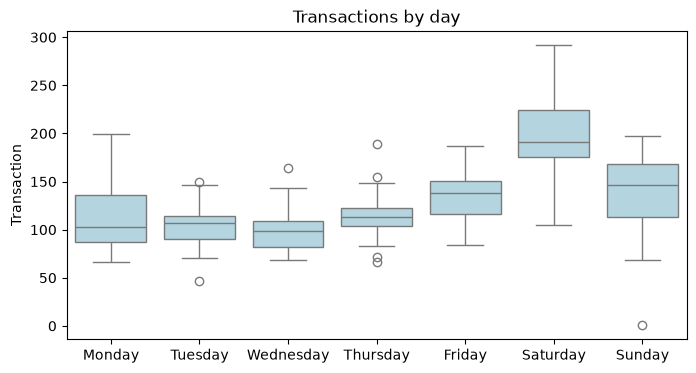

In [8]:
# Transactions by day of week

plt.figure(figsize=(8, 4))

transactions_by_day = items[['week_number', 'day_name', 'Transaction']].groupby(['week_number', 'day_name']).count()

sns.boxplot(x='day_name', y='Transaction', data=transactions_by_day, color='lightblue', 
            order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

plt.tick_params()
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('')
plt.title('Transactions by day')

Text(0.5, 1.0, 'Weekday vs weekend')

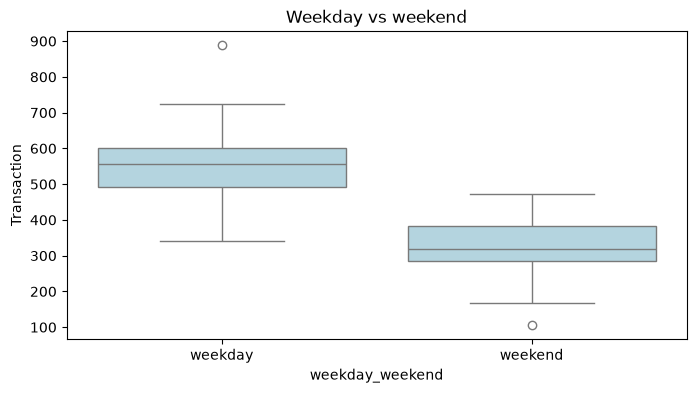

In [10]:
#  Transactions, weekday vs weekend

plt.figure(figsize=(8, 4))

transactions_weekday_weekend = items[['week_number', 'weekday_weekend', 'Transaction']].groupby(['week_number', 'weekday_weekend']).count()

sns.boxplot(x='weekday_weekend', y='Transaction', data=transactions_weekday_weekend, color='lightblue')

plt.ticklabel_format(style='plain', axis='y')
plt.title('Weekday vs weekend')

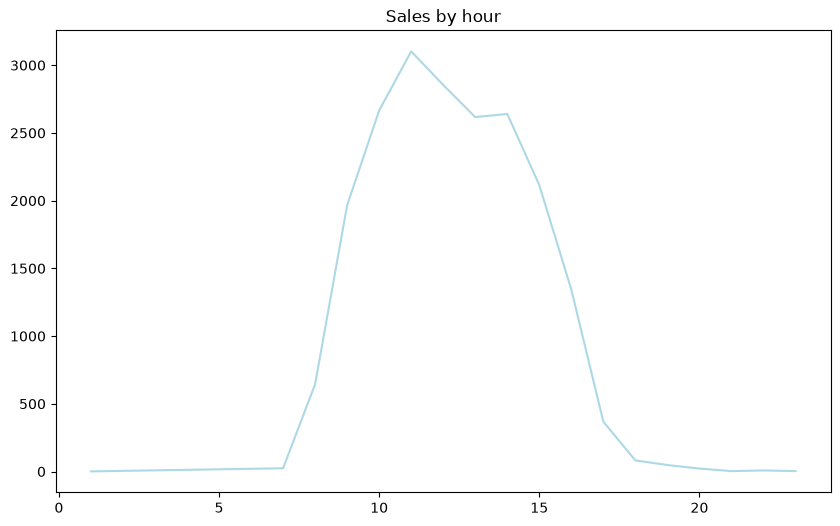

In [11]:
# Total transactions by hour

plt.figure(figsize=(10, 6))

transaction_by_hour = items[['hour', 'Transaction']].groupby('hour').count()

plt.ticklabel_format(style='plain', axis='y')

plt.title('Sales by hour')

#sns.barplot(x='hour', y='Transaction', data=transaction_by_hour, color='lightblue', native_scale=True)
plt.plot(transaction_by_hour, color='lightblue')


Text(0.5, 1.0, 'Top 10 most sold items')

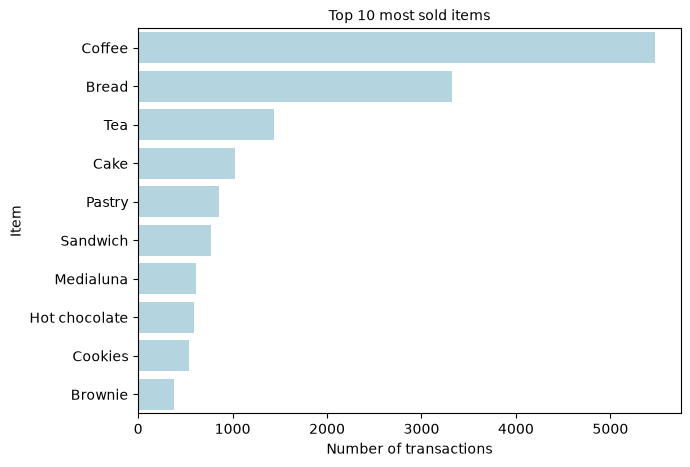

In [12]:
# Most sold items

fig, ax = plt.subplots(figsize=(7, 5))

transaction_by_items = items['Item'].value_counts().sort_values(ascending=False)

sns.barplot(transaction_by_items.head(10), orient='h', color='lightblue')

plt.xlabel('Number of transactions', fontsize=10)

ax.tick_params(labelsize=10)
plt.title('Top 10 most sold items', fontsize=10)

## Association Rule Mining

Use apriori algorithm for identifying frequent items and frequent item sets

Apriori: http://rasbt.github.io/mlxtend/api_subpackages/mlxtend.frequent_patterns/

Association rule mining: https://medium.com/@param.18156/understanding-association-rule-mining-a-key-tool-in-data-mining-97e81939b2ca 
and 
https://numiqo.com/tutorial/market-basket-analysis

Examples for association rules visuals: https://medium.com/delvify/a-conceptual-introduction-into-association-rule-mining-part-2-96c73c4ce87b

In [17]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

In [15]:
# item sets

items_per_transaction = items[['Item', 'Transaction']].groupby('Transaction').agg(lambda x: list(x)).reset_index()
items_per_transaction.rename(columns={'Item': 'Items'}, inplace=True)

items_per_transaction.head(10)

,Transaction,Items
0,1,[Bread]
1,2,"[Scandinavian, Scandinavian]"
2,3,"[Hot chocolate, Jam, Cookies]"
3,4,[Muffin]
4,5,"[Coffee, Pastry, Bread]"
5,6,"[Medialuna, Pastry, Muffin]"
6,7,"[Medialuna, Pastry, Coffee, Tea]"
7,8,"[Pastry, Bread]"
8,9,"[Bread, Muffin]"
9,10,"[Scandinavian, Medialuna]"


In [ ]:
# Sparse representation (one-hot)

transencoder = TransactionEncoder()
transencoder_array = transencoder.fit(items_per_transaction['Items']).transform(items_per_transaction['Items'])

In [19]:
items_df = pd.DataFrame(transencoder_array, columns=transencoder.columns_)

print(items_df.shape)
items_df.sample(10)

(9465, 94)


,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
8057,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2608,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3959,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
625,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
394,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4622,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2008,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3184,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
139,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7182,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [23]:
# transactions that include coffee - this is clearly a frequent item
coffee_df = items_df[items_df['Coffee'] == True]
coffee_df

,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
11,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
12,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
15,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9454,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9455,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9458,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
9462,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Generate frequent item sets
Choose min_support threshold

min_support = 0.1 : gives us only those item sets that are present in at least 10 % of transactions

In [24]:
items_frequent = apriori(items_df, min_support=0.1, use_colnames=True)
items_frequent

,support,itemsets
0,0.327205,frozenset({Bread})
1,0.103856,frozenset({Cake})
2,0.478394,frozenset({Coffee})
3,0.142631,frozenset({Tea})


In [25]:
items_frequent = apriori(items_df, min_support=0.09, use_colnames=True)
items_frequent

,support,itemsets
0,0.327205,frozenset({Bread})
1,0.103856,frozenset({Cake})
2,0.478394,frozenset({Coffee})
3,0.142631,frozenset({Tea})
4,0.090016,"frozenset({Coffee, Bread})"


In [30]:
items_frequent = apriori(items_df, min_support=0.05, use_colnames=True)
items_frequent.sort_values('support', ascending=False)

,support,itemsets
2,0.478394,frozenset({Coffee})
0,0.327205,frozenset({Bread})
8,0.142631,frozenset({Tea})
1,0.103856,frozenset({Cake})
9,0.090016,"frozenset({Coffee, Bread})"
6,0.086107,frozenset({Pastry})
7,0.071844,frozenset({Sandwich})
5,0.061807,frozenset({Medialuna})
4,0.058320,frozenset({Hot chocolate})
10,0.054728,"frozenset({Coffee, Cake})"


In [34]:
items_frequent = apriori(items_df, min_support=0.01, use_colnames=True)
items_frequent.sort_values('support', ascending=False)

,support,itemsets
6,0.478394,frozenset({Coffee})
2,0.327205,frozenset({Bread})
26,0.142631,frozenset({Tea})
4,0.103856,frozenset({Cake})
34,0.090016,"frozenset({Coffee, Bread})"
...,...,...
11,0.010565,frozenset({Hearty & Seasonal})
20,0.010460,frozenset({Salad})
30,0.010354,"frozenset({Alfajores, Bread})"
58,0.010037,"frozenset({Coffee, Cake, Bread})"


### Generating rules

In [35]:
# Based on metric confidence
# confidence(A->C): propability of seeing C in a transaction given that the transaction contains A

association = association_rules(items_frequent, metric='confidence', min_threshold=0.3)
association

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Alfajores}),frozenset({Coffee}),0.036344,0.478394,0.019651,0.540698,1.130235,1.0,0.002264,1.135648,0.119574,0.039693,0.119446,0.290888
1,frozenset({Pastry}),frozenset({Bread}),0.086107,0.327205,0.029160,0.338650,1.034977,1.0,0.000985,1.017305,0.036980,0.075908,0.017011,0.213884
2,frozenset({Brownie}),frozenset({Coffee}),0.040042,0.478394,0.019651,0.490765,1.025860,1.0,0.000495,1.024293,0.026259,0.039398,0.023717,0.265921
3,frozenset({Cake}),frozenset({Coffee}),0.103856,0.478394,0.054728,0.526958,1.101515,1.0,0.005044,1.102664,0.102840,0.103745,0.093105,0.320679
4,frozenset({Cookies}),frozenset({Coffee}),0.054411,0.478394,0.028209,0.518447,1.083723,1.0,0.002179,1.083174,0.081700,0.055905,0.076787,0.288707
5,frozenset({Hot chocolate}),frozenset({Coffee}),0.058320,0.478394,0.029583,0.507246,1.060311,1.0,0.001683,1.058553,0.060403,0.058333,0.055314,0.284542
6,frozenset({Juice}),frozenset({Coffee}),0.038563,0.478394,0.020602,0.534247,1.116750,1.0,0.002154,1.119919,0.108738,0.041507,0.107078,0.288656
7,frozenset({Medialuna}),frozenset({Coffee}),0.061807,0.478394,0.035182,0.569231,1.189878,1.0,0.005614,1.210871,0.170091,0.069665,0.174148,0.321387
8,frozenset({Muffin}),frozenset({Coffee}),0.038457,0.478394,0.018806,0.489011,1.022193,1.0,0.000408,1.020777,0.022579,0.037760,0.020354,0.264161
9,frozenset({Pastry}),frozenset({Coffee}),0.086107,0.478394,0.047544,0.552147,1.154168,1.0,0.006351,1.164682,0.146161,0.091968,0.141396,0.325764


In [38]:
# Based on metric lift
# lift: how much more often the antecendent and consequent of rule A -> C occur than we would expect 
# if they were statistically independent (lift = 1). 
# So we want to find all association rules where lift > 1. 

association = association_rules(items_frequent, metric='lift', min_threshold = 1)
association.sample(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Alfajores}),frozenset({Coffee}),0.036344,0.478394,0.019651,0.540698,1.130235,1.0,0.002264,1.135648,0.119574,0.039693,0.119446,0.290888
29,frozenset({Coffee}),frozenset({Spanish Brunch}),0.478394,0.018172,0.010882,0.022747,1.251766,1.0,0.002189,1.004682,0.385594,0.022406,0.004660,0.310792
28,frozenset({Spanish Brunch}),frozenset({Coffee}),0.018172,0.478394,0.010882,0.598837,1.251766,1.0,0.002189,1.300235,0.204851,0.022406,0.230908,0.310792
12,frozenset({Cookies}),frozenset({Coffee}),0.054411,0.478394,0.028209,0.518447,1.083723,1.0,0.002179,1.083174,0.081700,0.055905,0.076787,0.288707
1,frozenset({Coffee}),frozenset({Alfajores}),0.478394,0.036344,0.019651,0.041078,1.130235,1.0,0.002264,1.004936,0.220910,0.039693,0.004912,0.290888
6,frozenset({Coffee}),frozenset({Cake}),0.478394,0.103856,0.054728,0.114399,1.101515,1.0,0.005044,1.011905,0.176684,0.103745,0.011765,0.320679
11,frozenset({Tea}),frozenset({Cake}),0.142631,0.103856,0.023772,0.166667,1.604781,1.0,0.008959,1.075372,0.439556,0.106736,0.070090,0.197779
22,frozenset({Pastry}),frozenset({Coffee}),0.086107,0.478394,0.047544,0.552147,1.154168,1.0,0.006351,1.164682,0.146161,0.091968,0.141396,0.325764
20,frozenset({Coffee}),frozenset({Muffin}),0.478394,0.038457,0.018806,0.039311,1.022193,1.0,0.000408,1.000888,0.041623,0.037760,0.000888,0.264161
21,frozenset({Muffin}),frozenset({Coffee}),0.038457,0.478394,0.018806,0.489011,1.022193,1.0,0.000408,1.020777,0.022579,0.037760,0.020354,0.264161


In [202]:
association[association['confidence'] >= 0.5].sort_values('confidence', ascending = False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
30,frozenset({Toast}),frozenset({Coffee}),0.033597,0.478394,0.023666,0.704403,1.472431,1.0,0.007593,1.764582,0.332006,0.048464,0.433293,0.376936
28,frozenset({Spanish Brunch}),frozenset({Coffee}),0.018172,0.478394,0.010882,0.598837,1.251766,1.0,0.002189,1.300235,0.204851,0.022406,0.230908,0.310792
18,frozenset({Medialuna}),frozenset({Coffee}),0.061807,0.478394,0.035182,0.569231,1.189878,1.0,0.005614,1.210871,0.170091,0.069665,0.174148,0.321387
22,frozenset({Pastry}),frozenset({Coffee}),0.086107,0.478394,0.047544,0.552147,1.154168,1.0,0.006351,1.164682,0.146161,0.091968,0.141396,0.325764
0,frozenset({Alfajores}),frozenset({Coffee}),0.036344,0.478394,0.019651,0.540698,1.130235,1.0,0.002264,1.135648,0.119574,0.039693,0.119446,0.290888
17,frozenset({Juice}),frozenset({Coffee}),0.038563,0.478394,0.020602,0.534247,1.116750,1.0,0.002154,1.119919,0.108738,0.041507,0.107078,0.288656
25,frozenset({Sandwich}),frozenset({Coffee}),0.071844,0.478394,0.038246,0.532353,1.112792,1.0,0.003877,1.115384,0.109205,0.074701,0.103448,0.306150
7,frozenset({Cake}),frozenset({Coffee}),0.103856,0.478394,0.054728,0.526958,1.101515,1.0,0.005044,1.102664,0.102840,0.103745,0.093105,0.320679
26,frozenset({Scone}),frozenset({Coffee}),0.034548,0.478394,0.018067,0.522936,1.093107,1.0,0.001539,1.093366,0.088224,0.036507,0.085393,0.280350
13,frozenset({Cookies}),frozenset({Coffee}),0.054411,0.478394,0.028209,0.518447,1.083723,1.0,0.002179,1.083174,0.081700,0.055905,0.076787,0.288707


In [39]:
association[association['antecedents'] == {'Cake'}]

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
7,frozenset({Cake}),frozenset({Coffee}),0.103856,0.478394,0.054728,0.526958,1.101515,1.0,0.005044,1.102664,0.102840,0.103745,0.093105,0.320679
9,frozenset({Cake}),frozenset({Hot chocolate}),0.103856,0.058320,0.011410,0.109868,1.883874,1.0,0.005354,1.057910,0.523553,0.075683,0.054740,0.152760
10,frozenset({Cake}),frozenset({Tea}),0.103856,0.142631,0.023772,0.228891,1.604781,1.0,0.008959,1.111865,0.420538,0.106736,0.100611,0.197779
35,frozenset({Cake}),"frozenset({Coffee, Bread})",0.103856,0.090016,0.010037,0.096643,1.073621,1.0,0.000688,1.007336,0.076520,0.054598,0.007283,0.104073
40,frozenset({Cake}),"frozenset({Coffee, Tea})",0.103856,0.049868,0.010037,0.096643,1.937977,1.0,0.004858,1.051779,0.540090,0.069853,0.049230,0.148957


In [40]:
association[association['antecedents'] == {'Coffee'}]

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
1,frozenset({Coffee}),frozenset({Alfajores}),0.478394,0.036344,0.019651,0.041078,1.130235,1.0,0.002264,1.004936,0.220910,0.039693,0.004912,0.290888
4,frozenset({Coffee}),frozenset({Brownie}),0.478394,0.040042,0.019651,0.041078,1.025860,1.0,0.000495,1.001080,0.048327,0.039398,0.001079,0.265921
6,frozenset({Coffee}),frozenset({Cake}),0.478394,0.103856,0.054728,0.114399,1.101515,1.0,0.005044,1.011905,0.176684,0.103745,0.011765,0.320679
13,frozenset({Coffee}),frozenset({Cookies}),0.478394,0.054411,0.028209,0.058966,1.083723,1.0,0.002179,1.004841,0.148110,0.055905,0.004818,0.288707
14,frozenset({Coffee}),frozenset({Hot chocolate}),0.478394,0.058320,0.029583,0.061837,1.060311,1.0,0.001683,1.003749,0.109048,0.058333,0.003735,0.284542
16,frozenset({Coffee}),frozenset({Juice}),0.478394,0.038563,0.020602,0.043065,1.116750,1.0,0.002154,1.004705,0.200428,0.041507,0.004683,0.288656
19,frozenset({Coffee}),frozenset({Medialuna}),0.478394,0.061807,0.035182,0.073542,1.189878,1.0,0.005614,1.012667,0.305936,0.069665,0.012509,0.321387
20,frozenset({Coffee}),frozenset({Muffin}),0.478394,0.038457,0.018806,0.039311,1.022193,1.0,0.000408,1.000888,0.041623,0.037760,0.000888,0.264161
23,frozenset({Coffee}),frozenset({Pastry}),0.478394,0.086107,0.047544,0.099382,1.154168,1.0,0.006351,1.014740,0.256084,0.091968,0.014526,0.325764
24,frozenset({Coffee}),frozenset({Sandwich}),0.478394,0.071844,0.038246,0.079947,1.112792,1.0,0.003877,1.008807,0.194321,0.074701,0.008731,0.306150


In [41]:
association[association['consequents'] == {'Bread', 'Coffee'}]

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
35,frozenset({Cake}),"frozenset({Coffee, Bread})",0.103856,0.090016,0.010037,0.096643,1.073621,1.0,0.000688,1.007336,0.076520,0.054598,0.007283,0.104073
37,frozenset({Pastry}),"frozenset({Coffee, Bread})",0.086107,0.090016,0.011199,0.130061,1.444872,1.0,0.003448,1.046033,0.336907,0.067905,0.044007,0.127237
